# Ideas

1. **Image Preprocessing**
    -   **Dataset Augmentation**
        *   x10 the training dataset
    -   Grayscaling
        *   Primarily reduce the computational power
2. **Intuitively Group Age Classes**
    -   Roblox: 5-8, 9-12, 13-15, 16-17, 18-20, and 21+
    -   Business-wise, we have to add more label for 21+
    -   Suggestion for 21+ group: 21-27, 28-45, 46-65, 66+
        -   21-27 years: Categorized as mature adults.
        -   28-45 years: Representing the adult stage of life.
        -   46-65 years: Distinguished by the appearance of more pronounced aging features.
        -   66+ years: Represented by features like graying hair and aging skin.
3. Use CNN-Based Deep Learning Aproach


Proposed labels: 1-4, 5-8, 9-12, 13-15, 16-17, 18-20, 21-27, 28-45, 46-65, 66+

# Import Libraries and Setup Environments

In [1]:
# Standard libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

# For CNN
from keras.preprocessing.image import load_img
from keras import mixed_precision
from keras.models import Sequential, Model
from keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, concatenate
from keras.optimizers import SGD, Adam
from keras.callbacks import ReduceLROnPlateau, EarlyStopping
from keras.applications import MobileNetV2, ResNet50, VGG16, MobileNetV2, DenseNet121

# For loading and preprocessing dataset(s) and others
import os
#import cv2
import glob
#import imagehash
#from tqdm.notebook import tqdm
#from PIL import Image

I0000 00:00:1792783900.752162  108149 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792783900.796359  108149 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792783901.653292  108149 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import kagglehub

#facial_age_path = kagglehub.dataset_download("frabbisw/facial-age", output_dir="/home/sisi/projects/age-estimation/data/raw/facial-age-ver1")
#utk_path = kagglehub.dataset_download("jangedoo/utkface-new", output_dir="/home/sisi/projects/age-estimation/data/raw/UTKFace", force_download=True)

utk_path = "/home/sisi/projects/age-estimation/data/raw/UTKFace"
facial_age_path = "/home/sisi/projects/age-estimation/data/raw/facial-age-ver1"

print(facial_age_path)
print(utk_path)

/home/sisi/projects/age-estimation/data/raw/facial-age-ver1
/home/sisi/projects/age-estimation/data/raw/UTKFace


In [3]:
gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("GPU devices:", gpus)

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# This will reduce the VRAM consumed
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
    print("GPU Memory Growth Enabled!")

GPU Memory Growth Enabled!


In [5]:
mixed_precision.set_global_policy("mixed_float16")

# Load the Dataset

## UTKFace


In [6]:
# The UTKFace dataset filenames are formatted as [age]_[gender]_[race]_[date&time].jpg
utk_image_paths:list = glob.glob(os.path.join(utk_path, 'UTKFace', '*.jpg'))
# if not image_paths:
#     image_paths = glob.glob(os.path.join(utk_path, '*/*.jpg')) + glob.glob(os.path.join(utk_path, '*.jpg'))

#print((image_paths[0:9]))
print(f"Total images found: {len(utk_image_paths)}")

# Create a DataFrame
data = []
for path in utk_image_paths:
    filename = os.path.basename(path)
    parts = filename.split('_')
    if len(parts) >= 3:
        try:
            age = int(parts[0])
            data.append({'path': path, 'age': age})
        except ValueError:
            continue

df_utk = pd.DataFrame(data)
display(df_utk.head())

Total images found: 23708


,path,age
0,/home/sisi/projects/age-estimation/data/raw/UT...,39
1,/home/sisi/projects/age-estimation/data/raw/UT...,23
2,/home/sisi/projects/age-estimation/data/raw/UT...,26
3,/home/sisi/projects/age-estimation/data/raw/UT...,31
4,/home/sisi/projects/age-estimation/data/raw/UT...,42


## facial age (version 1)

In [7]:
# The facial-age dataset contains of sub-folders in /facial-age-ver1/face-age/ and /facial-age-ver1/face_age/face_age/. Both will lead to multiple sub-folders named after an integer, in which contains the .png files

f_a_image_paths = glob.glob(os.path.join(facial_age_path, 'face_age/face_age', '*/*.png')) # We will just get the folders here


# Create a DataFrame
f_a_data = []
for path in f_a_image_paths:
    parts = path.split('/')
    try:
        age = int(parts[-2])
        f_a_data.append({'path': path, 'age': age})
    except:
        continue

print(f"Total images found: {len(f_a_image_paths)}")

df_f_a = pd.DataFrame(f_a_data)
display(df_f_a.head())

Total images found: 9778


,path,age
0,/home/sisi/projects/age-estimation/data/raw/fa...,46
1,/home/sisi/projects/age-estimation/data/raw/fa...,46
2,/home/sisi/projects/age-estimation/data/raw/fa...,46
3,/home/sisi/projects/age-estimation/data/raw/fa...,46
4,/home/sisi/projects/age-estimation/data/raw/fa...,46


## Combine 2 datasets


In [8]:
df = pd.concat([df_f_a, df_utk], ignore_index=True)
print(df.shape)

(33486, 2)


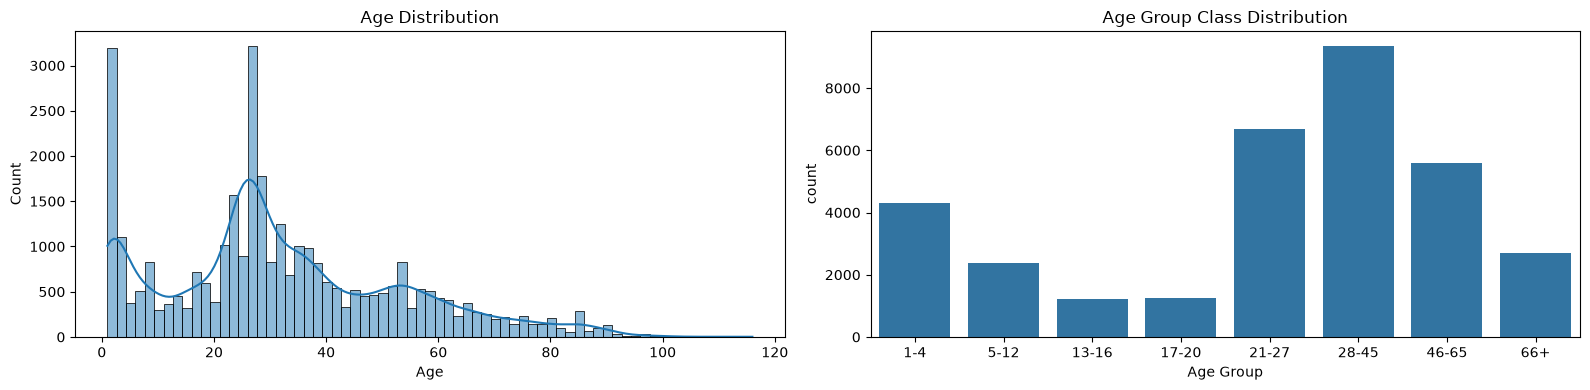

In [9]:
def map_age_to_class(age):
    if age <= 4:    return 0    # 1-4
    elif age <= 12: return 1    # 5-12
    elif age <= 16: return 2    # 13-16
    elif age <= 20: return 3    # 17-20
    elif age <= 27: return 4    # 21-27
    elif age <= 45: return 5    # 28-45
    elif age <= 65: return 6    # 46-65
    else: return 7              # 66+

df['label'] = df['age'].apply(map_age_to_class)

class_names = ['1-4', '5-12', '13-16', '17-20', '21-27', '28-45', '46-65', '66+']
num_classes = len(class_names)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))
sns.histplot(data=df, x='age', kde=True, ax=ax1)
ax1.set_title('Age Distribution')
ax1.set_xlabel('Age')

sns.countplot(x='label', data=df, ax=ax2)
ax2.set_xticks(range(len(class_names)), labels=class_names)
ax2.set_title('Age Group Class Distribution')
ax2.set_xlabel('Age Group')

plt.tight_layout()
plt.show()


# Train-Test Split & tf.data Pipeline with Augmentation

In [10]:
from sklearn.model_selection import train_test_split

# Train/Val/Test split (80/10/10)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
val_df, test_df = train_test_split(test_df, test_size=0.5, random_state=42, stratify=test_df['label'])

IMG_SIZE = 128
BATCH_SIZE = 64
EPOCHS = 50  # Can be increased for better convergence

def parse_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(1/18),
    tf.keras.layers.RandomZoom(0.1),
])

train_ds = tf.data.Dataset.from_tensor_slices((train_df['path'].values, train_df['label'].values))
train_ds = train_ds.shuffle(len(train_df)).map(parse_image, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_df['path'].values, val_df['label'].values))
val_ds = val_ds.map(parse_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1792783903.083475  108149 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13549 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Ti SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


# Model 1: Simple CNN Architecture

In [11]:
simple_model = Sequential(
    [
        Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

        Conv2D(16, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(32, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        Conv2D(128, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        Conv2D(256, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),

        GlobalAveragePooling2D(),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(8, activation='softmax')
    ],
    name="SimpleCNN"
)

simple_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
simple_model.summary()

Model: "SimpleCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 495,336 (1.89 MB)

 Trainable params: 493,832 (1.88 MB)

 Non-trainable params: 1,504 (5.88 KB)

In [12]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=3, min_lr=1e-8, verbose=1)

In [13]:
print("Training Simple CNN...")
history_simple = simple_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
	verbose=1
)

Training Simple CNN...
Epoch 1/50


/home/sisi/projects/age-estimation/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1792783903.987767  108149 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.
I0000 00:00:1792783906.311106  108620 service.cc:153] XLA service 0x7537e4014e80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792783906.311125  108620 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 Ti SUPER, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792783906.403500  108620 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env v

416/419 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3591 - loss: 1.7394

I0000 00:00:1792783930.649677  108617 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_7020__.130
I0000 00:00:1792783930.930771  108617 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792783931.186638  109236 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1792783931.210871  109241 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 40 bytes spill stores, 40 bytes spill loads

I0000 00:00:1792783934.542935  108617 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a g

419/419 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.3598 - loss: 1.7370

I0000 00:00:1792783944.026905  108619 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792783944.409765  108619 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


419/419 ━━━━━━━━━━━━━━━━━━━━ 44s 63ms/step - accuracy: 0.3598 - loss: 1.7370 - val_accuracy: 0.3810 - val_loss: 1.6824 - learning_rate: 0.0010
Epoch 2/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.4906 - loss: 1.2852 - val_accuracy: 0.2039 - val_loss: 3.9678 - learning_rate: 0.0010
Epoch 3/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.5394 - loss: 1.1522 - val_accuracy: 0.5584 - val_loss: 1.1129 - learning_rate: 0.0010
Epoch 4/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.5628 - loss: 1.0751 - val_accuracy: 0.5127 - val_loss: 1.2652 - learning_rate: 0.0010
Epoch 5/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.5849 - loss: 1.0224 - val_accuracy: 0.4990 - val_loss: 1.4461 - learning_rate: 0.0010
Epoch 6/50
417/419 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5923 - loss: 0.9919
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.5926 - loss: 0.9919 - v

# Model 2: Complex CNN Architecture (VGG block style)

In [14]:
def build_complex_cnn():
    # Implementing a scratch VGG-style deep block structure
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Block 1 (VGG Block)
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)
    x = Dropout(0.2)(x)

    # Block 2 (VGG Block)
    x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)
    x = Dropout(0.25)(x)

    # Block 3 (VGG Block)
    x = Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)
    x = Dropout(0.3)(x)

    # Block 4 (VGG Block)
    x = Conv2D(512, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(512, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)
    x = Dropout(0.3)(x)

    # Block 5 (VGG Block)
    x = Conv2D(512, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Conv2D(512, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=(2, 2))(x)
    x = Dropout(0.3)(x)

    # Fully Connected layers
    x = GlobalAveragePooling2D()(x)
    x = Dense(1024, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    x = Dense(512, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)

    outputs = Dense(8, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs, name='VGG_Scratch_ComplexCNN')
    return model

complex_model = build_complex_cnn()
complex_model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
complex_model.summary()

Model: "VGG_Scratch_ComplexCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,80

 Total params: 10,291,848 (39.26 MB)

 Trainable params: 10,283,272 (39.23 MB)

 Non-trainable params: 8,576 (33.50 KB)

In [15]:
print("Training Complex CNN...")
history_complex = complex_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Training Complex CNN...
Epoch 1/50


I0000 00:00:1792784251.917516  108617 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_80211__.176


417/419 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2226 - loss: 2.7359

I0000 00:00:1792784293.047164  108617 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_80211__.176


419/419 ━━━━━━━━━━━━━━━━━━━━ 73s 102ms/step - accuracy: 0.2227 - loss: 2.7353 - val_accuracy: 0.1678 - val_loss: 2.8576 - learning_rate: 1.0000e-04
Epoch 2/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.3284 - loss: 2.1268 - val_accuracy: 0.3231 - val_loss: 2.8081 - learning_rate: 1.0000e-04
Epoch 3/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.4037 - loss: 1.7120 - val_accuracy: 0.2275 - val_loss: 3.3465 - learning_rate: 1.0000e-04
Epoch 4/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.4437 - loss: 1.4733 - val_accuracy: 0.4613 - val_loss: 1.7107 - learning_rate: 1.0000e-04
Epoch 5/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.4798 - loss: 1.3353 - val_accuracy: 0.3992 - val_loss: 3.0020 - learning_rate: 1.0000e-04
Epoch 6/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.5060 - loss: 1.2428 - val_accuracy: 0.4751 - val_loss: 1.4542 - learning_rate: 1.0000e-04
Epoch 7/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accura

# Model 3: Transfer Learning (MobileNetV2 Fine-tuning)

In [16]:
def build_transfer_learning_model():
    base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
    base_model.trainable = False  # Freeze base model layers initially

    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    # Scale inputs between [-1, 1] as expected by MobileNetV2
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)

    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)

    outputs = Dense(8, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs, name="Transfer_FineTuned_CNN")
    return model, base_model

transfer_model, base_model = build_transfer_learning_model()
transfer_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
transfer_model.summary()

Model: "Transfer_FineTuned_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
print("Training Transfer Learning Model...")
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
	verbose=1
)

Training Transfer Learning Model...
Epoch 1/50


I0000 00:00:1792785028.972541  108615 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_184291__.126


414/419 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4582 - loss: 1.4086

I0000 00:00:1792785044.966374  108619 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_184291__.126


419/419 ━━━━━━━━━━━━━━━━━━━━ 31s 51ms/step - accuracy: 0.4588 - loss: 1.4076 - val_accuracy: 0.5172 - val_loss: 1.2004 - learning_rate: 0.0010
Epoch 2/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.5176 - loss: 1.2195 - val_accuracy: 0.5258 - val_loss: 1.1984 - learning_rate: 0.0010
Epoch 3/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.5331 - loss: 1.1681 - val_accuracy: 0.5372 - val_loss: 1.1596 - learning_rate: 0.0010
Epoch 4/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.5365 - loss: 1.1640 - val_accuracy: 0.5309 - val_loss: 1.1460 - learning_rate: 0.0010
Epoch 5/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.5442 - loss: 1.1419 - val_accuracy: 0.5449 - val_loss: 1.1363 - learning_rate: 0.0010
Epoch 6/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.5459 - loss: 1.1408 - val_accuracy: 0.5411 - val_loss: 1.1387 - learning_rate: 0.0010
Epoch 7/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.5510 - loss: 1.1237

In [18]:
print("Unfreezing MobileNetV2 base model layers for fine-tuning...")
base_model.trainable = True

# Freeze all layers up to layer 100
for layer in base_model.layers[:100]:
    layer.trainable = False

# Re-compile with a very small learning rate for fine-tuning
transfer_model.compile(
    optimizer=Adam(learning_rate=1e-5), 
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy']
)

transfer_model.summary()

Unfreezing MobileNetV2 base model layers for fine-tuning...


Model: "Transfer_FineTuned_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 1,871,688 (7.14 MB)

 Non-trainable params: 396,544 (1.51 MB)

In [19]:
print("Fine-tuning MobileNetV2 model...")
history_transfer_finetune = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,  # Fine-tuning usually requires fewer epochs
    callbacks=[early_stopping, reduce_lr],
    shuffle=True,
	verbose=1
)

Fine-tuning MobileNetV2 model...
Epoch 1/50


I0000 00:00:1792785369.017721  108620 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_268777__.252


416/419 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3926 - loss: 1.9094

I0000 00:00:1792785395.086119  108614 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_268777__.252


419/419 ━━━━━━━━━━━━━━━━━━━━ 52s 70ms/step - accuracy: 0.3932 - loss: 1.9063 - val_accuracy: 0.5016 - val_loss: 1.2942 - learning_rate: 1.0000e-05
Epoch 2/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.4857 - loss: 1.4663 - val_accuracy: 0.5148 - val_loss: 1.2831 - learning_rate: 1.0000e-05
Epoch 3/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.5174 - loss: 1.3181 - val_accuracy: 0.5399 - val_loss: 1.2331 - learning_rate: 1.0000e-05
Epoch 4/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.5345 - loss: 1.2226 - val_accuracy: 0.5485 - val_loss: 1.1951 - learning_rate: 1.0000e-05
Epoch 5/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.5509 - loss: 1.1371 - val_accuracy: 0.5629 - val_loss: 1.1301 - learning_rate: 1.0000e-05
Epoch 6/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.5735 - loss: 1.0827 - val_accuracy: 0.5814 - val_loss: 1.0821 - learning_rate: 1.0000e-05
Epoch 7/50
419/419 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accurac

# Model 4: The Ultimate Model
The input is divided into branches, each is applied with a modern CNN model, then GlobalAveragePooling, and finally, all branches are concatenated into one Fully Connected layer

In [20]:
def inception_block(input, filters_1x1, filters_3x3_tuple: tuple, filters_5x5_tuple: tuple, filters_pool_proj):
    # Branch A: 1x1 Conv
    branch1 = Conv2D(filters_1x1, (1, 1), padding='same', activation='silu')(input)

    # Branch B: 1x1 Conv -> 3x3 Conv
    filters_3x3_reduce, filters_3x3 = filters_3x3_tuple
    branch2 = Conv2D(filters_3x3_reduce, (1, 1), padding='same', activation='relu')(input)
    branch2 = Conv2D(filters_3x3, (3, 3), padding='same', activation='relu')(branch2)

    # Branch C: 1x1 Conv -> 5x5 Conv
    filters_5x5_reduce, filters_5x5 = filters_5x5_tuple
    branch3 = Conv2D(filters_5x5_reduce, (1, 1), padding='same', activation='relu')(input)
    branch3 = Conv2D(filters_5x5, (5, 5), padding='same', activation='relu')(branch3)

    # Branch D: 3x3 MaxPool -> 1x1 Conv
    branch4 = MaxPooling2D((3, 3), strides=(1, 1), padding='same')(input)
    branch4 = Conv2D(filters_pool_proj, (1, 1), padding='same', activation='relu')(branch4)

    # Concatenate inception paths
    output = concatenate([branch1, branch2, branch3, branch4], axis=-1)
    return output

In [21]:
def build_ultimate_fusion_model(img_size=128, num_classes=10):
    inputs = Input(shape=(img_size, img_size, 3))

    
    # 1. MobileNetV2 Feature Extraction Branch
    mobilenet_base = MobileNetV2(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')
    mobilenet_base.trainable = False
    x_mobilenet = mobilenet_base(inputs, training=False)
    x_mobilenet_pooled = GlobalAveragePooling2D()(x_mobilenet)

    
    # 2. ResNet50 Feature Extraction Branch
    resnet_base = ResNet50(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')
    resnet_base.trainable = False
    x_resnet = resnet_base(inputs, training=False)
    x_resnet_pooled = GlobalAveragePooling2D()(x_resnet)

    
    # 3. DenseNet121 Feature Extraction Branch
    densenet_base = DenseNet121(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')
    densenet_base.trainable = False
    x_densenet = densenet_base(inputs, training=False)
    x_densenet_pooled = GlobalAveragePooling2D()(x_densenet)

    
    # 4. AlexNet Full (Large Kernels + MaxPool)
    x_alex = Conv2D(96, (11, 11), strides=(4, 4), padding='same', activation='silu')(inputs)
    x_alex = BatchNormalization()(x_alex)
    x_alex = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_alex)

    x_alex = Conv2D(256, (5, 5), padding='same', activation='silu')(x_alex)
    x_alex = BatchNormalization()(x_alex)
    x_alex = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_alex)

    x_alex = Conv2D(384, (3, 3), padding='same', activation='silu')(x_alex)
    x_alex = Conv2D(384, (3, 3), padding='same', activation='silu')(x_alex)
    x_alex = Conv2D(384, (3, 3), padding='same', activation='silu')(x_alex)
    x_alex = BatchNormalization()(x_alex)
    x_alex = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_alex)

    x_alex_pooled = GlobalAveragePooling2D()(x_alex)

    
    # 5. VGG16 Feature Extraction Branch (Pre-trained)
    vgg_base = VGG16(input_shape=(img_size, img_size, 3), include_top=False, weights='imagenet')
    vgg_base.trainable = False
    x_vgg = vgg_base(inputs, training=False)
    x_vgg_pooled = GlobalAveragePooling2D()(x_vgg)

    
    # 6. NiN (Network In Network) Full (1x1 Convolutions)
    x_nin = Conv2D(96, (11, 11), strides=(4, 4), padding='same', activation='silu')(inputs)
    x_nin = Conv2D(96, (1, 1), strides=(4, 4), padding='same', activation='silu')(inputs)
    x_nin = Conv2D(96, (1, 1), strides=(4, 4), padding='same', activation='silu')(inputs)
    x_nin = BatchNormalization()(x_nin)
    x_nin = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_nin)

    x_nin = Conv2D(256, (5, 5), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(256, (1, 1), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(256, (1, 1), activation='silu', padding='same')(x_nin)
    x_nin = BatchNormalization()(x_nin)
    x_nin = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_nin)

    x_nin = Conv2D(384, (3, 3), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(384, (1, 1), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(384, (3, 3), activation='silu', padding='same')(x_nin)
    x_nin = BatchNormalization()(x_nin)
    x_nin = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_nin)

    x_nin = Conv2D(10, (3, 3), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(10, (1, 1), activation='silu', padding='same')(x_nin)
    x_nin = Conv2D(10, (3, 3), activation='silu', padding='same')(x_nin)
    x_nin = BatchNormalization()(x_nin)
    x_nin = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_nin)

    x_nin_pooled = GlobalAveragePooling2D()(x_nin)
    x_nin_pooled = Dropout(0.5)(x_nin_pooled)

    
    # 7. GoogLeNet Full (Inception Blocks)
    x_google_net = Conv2D(64, (7, 7), strides=(2, 2), padding='same', activation='silu')(inputs)
    x_google_net = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_google_net)

    x_google_net = Conv2D(64, (1, 1), padding='same', activation='silu')(inputs)
    x_google_net = Conv2D(192, (3, 3), padding='same', activation='silu')(inputs)
    x_google_net = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_google_net)

    x_google_net = inception_block(x_google_net, 64, (96, 128), (16, 32), 32)
    x_google_net = inception_block(x_google_net, 128, (128, 192), (32, 96), 64)
    x_google_net = MaxPooling2D((3, 3), strides=(2, 2), padding='same')(x_google_net)

    x_google_net = inception_block(x_google_net, 192, (96, 208), (16, 48), 64)
    x_google_net = inception_block(x_google_net, 160, (112, 224), (24, 64), 64)
    x_google_net = inception_block(x_google_net, 128, (128, 256), (24, 64), 64)
    x_google_net = inception_block(x_google_net, 112, (144, 288), (32, 64), 64)
    x_google_net = inception_block(x_google_net, 256, (160, 320), (32, 128), 128)
    x_google_net = MaxPooling2D((3, 3), strides=(2, 2), padding='same') (x_google_net)

    x_google_net = inception_block(x_google_net, 256, (160, 320), (32, 128), 128)
    x_google_net = inception_block(x_google_net, 384, (192, 384), (48, 128), 128)
    x_google_net = GlobalAveragePooling2D()(x_google_net)
    x_googlenet_pooled = Dropout(.4)(x_google_net)

    
    # FUSION HEAD: Concatenate representations from all 7 models!
    fused_features = concatenate([
        x_mobilenet_pooled,
        x_resnet_pooled,
        x_densenet_pooled,
        x_alex_pooled,
        x_vgg_pooled,
        x_nin_pooled,
        x_googlenet_pooled,
    ])

    # Dense Classification layers
    x = Dense(1024, activation='silu')(fused_features)
    x = BatchNormalization()(x)
    x = Dense(512, activation='silu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    outputs = Dense(num_classes, activation='softmax', dtype='float32')(x)

    model = Model(inputs=inputs, outputs=outputs, name='Ultimate_Fusion_Net')
    return model

# Instantiate and compile
ultimate_model = build_ultimate_fusion_model(img_size=IMG_SIZE, num_classes=8)
ultimate_model.compile(optimizer=Adam(learning_rate=1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Print parameter size to inspect our mega-model
ultimate_model.summary()

Model: "Ultimate_Fusion_Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 128, 128,  │      5,376 │ input_layer_5[0]… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_18    │ (None, 64, 64,    │          0 │ conv2d_32[0][0]   │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 64, 64,    │     18,528 │ max_pooling2d_18… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 64, 64,    │      3,088 │ max_pooling2d_18… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_19    │ (None, 64, 64,    │          0 │ max_pooling2d_18… │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 64, 64,    │     12,352 │ max_pooling2d_18… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 64, 64,    │    110,720 │ conv2d_34[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 64, 64,    │     12,832 │ conv2d_36[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 64, 64,    │      6,176 │ max_pooling2d_19… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ conv2d_33[0][0],  │
│ (Concatenate)       │ 256)              │            │ conv2d_35[0][0],  │
│                     │                   │            │ conv2d_37[0][0],  │
│                     │                   │            │ conv2d_38[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 64, 64,    │     32,896 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 64, 64,    │      8,224 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_20    │ (None, 64, 64,    │          0 │ concatenate[0][0] │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 64, 64,    │     32,896 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 64, 64,    │    221,376 │ conv2d_40[0][0]   │
│                     │ 192)              │            │                 

 Total params: 67,759,526 (258.48 MB)

 Trainable params: 20,155,602 (76.89 MB)

 Non-trainable params: 47,603,924 (181.59 MB)

In [22]:
print("Training Ultimate Fusion Net (7 fused architectures)...")
history_ultimate = ultimate_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
	verbose=1
)

Training Ultimate Fusion Net (7 fused architectures)...
Epoch 1/60


I0000 00:00:1792785981.937106  108619 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_464641__.1082
I0000 00:00:1792786005.157390  127154 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 8 bytes spill stores, 4 bytes spill loads

I0000 00:00:1792786031.872634  127155 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_convert_transpose_fusion_10', 4 bytes spill stores, 4 bytes spill loads



418/419 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.3818 - loss: 1.9490

I0000 00:00:1792786138.481420  108618 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_464641__.1082


419/419 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step - accuracy: 0.3819 - loss: 1.9485

I0000 00:00:1792786245.333091  135095 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 4 bytes spill stores, 4 bytes spill loads



419/419 ━━━━━━━━━━━━━━━━━━━━ 314s 466ms/step - accuracy: 0.3819 - loss: 1.9485 - val_accuracy: 0.4234 - val_loss: 1.6415 - learning_rate: 1.0000e-05
Epoch 2/60
419/419 ━━━━━━━━━━━━━━━━━━━━ 72s 172ms/step - accuracy: 0.4691 - loss: 1.5478 - val_accuracy: 0.5324 - val_loss: 1.2499 - learning_rate: 1.0000e-05
Epoch 3/60
419/419 ━━━━━━━━━━━━━━━━━━━━ 73s 173ms/step - accuracy: 0.4987 - loss: 1.4176 - val_accuracy: 0.5312 - val_loss: 1.2385 - learning_rate: 1.0000e-05
Epoch 4/60
419/419 ━━━━━━━━━━━━━━━━━━━━ 76s 182ms/step - accuracy: 0.5174 - loss: 1.3505 - val_accuracy: 0.5632 - val_loss: 1.1363 - learning_rate: 1.0000e-05
Epoch 5/60
419/419 ━━━━━━━━━━━━━━━━━━━━ 77s 182ms/step - accuracy: 0.5341 - loss: 1.2872 - val_accuracy: 0.5838 - val_loss: 1.0914 - learning_rate: 1.0000e-05
Epoch 6/60
419/419 ━━━━━━━━━━━━━━━━━━━━ 77s 183ms/step - accuracy: 0.5508 - loss: 1.2214 - val_accuracy: 0.5829 - val_loss: 1.0716 - learning_rate: 1.0000e-05
Epoch 7/60
419/419 ━━━━━━━━━━━━━━━━━━━━ 77s 183ms/step -

# Model Evaluation & Comparison

In [23]:
models_history = {
    'Simple CNN': 'history_simple',
    'Complex CNN': 'history_complex',
    'Transfer Learning (Base)': 'history_transfer',
    'Transfer Learning (Fine-Tuned)': 'history_transfer_finetune',
    'Ultimate Fusion Net': 'history_ultimate'
}

print("=== Final Validation Performance Summary ===")
for name, var_name in models_history.items():
    if var_name in globals():
        hist = globals()[var_name].history
        final_val_loss = hist['val_loss'][-1]
        final_val_acc = hist['val_accuracy'][-1]
        print(f"{name}:")
        print(f"  - Val Loss: {final_val_loss:.4f}")
        print(f"  - Val Accuracy: {final_val_acc:.4f}")
        print()
    else:
        print(f"{name}: Not trained/not found in workspace.\n")

=== Final Validation Performance Summary ===
Simple CNN:
  - Val Loss: 0.8000
  - Val Accuracy: 0.6596

Complex CNN:
  - Val Loss: 0.7183
  - Val Accuracy: 0.7095

Transfer Learning (Base):
  - Val Loss: 1.1068
  - Val Accuracy: 0.5452

Transfer Learning (Fine-Tuned):
  - Val Loss: 0.7682
  - Val Accuracy: 0.6892

Ultimate Fusion Net:
  - Val Loss: 0.8470
  - Val Accuracy: 0.6596



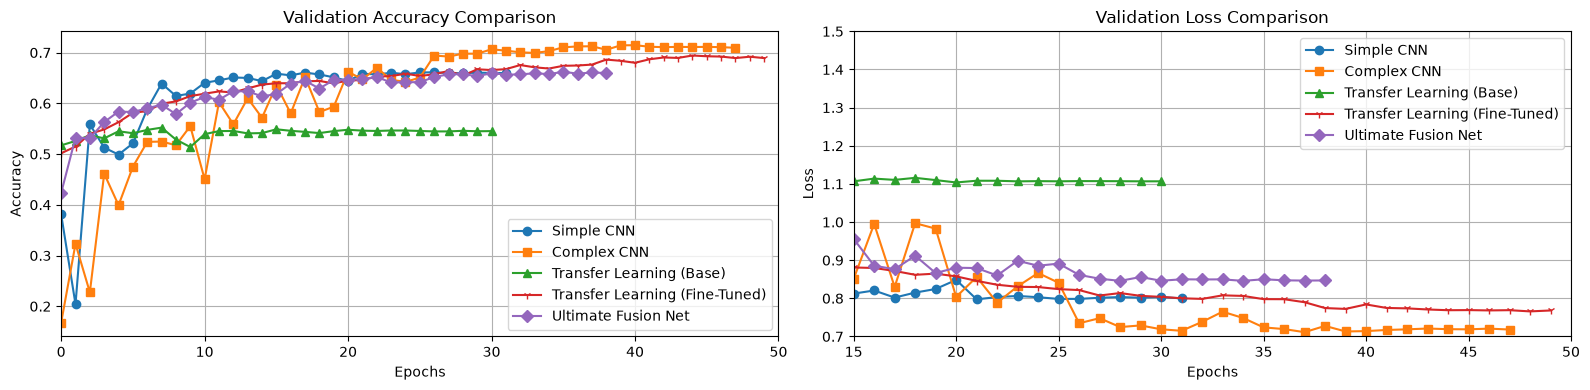

In [29]:
# Setup plotting comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))

# Accuracy comparison
ax1.plot(history_simple.history['val_accuracy'], label='Simple CNN', marker='o')
ax1.plot(history_complex.history['val_accuracy'], label='Complex CNN', marker='s')
ax1.plot(history_transfer.history['val_accuracy'], label='Transfer Learning (Base)', marker='^')
ax1.plot(history_transfer_finetune.history['val_accuracy'], label='Transfer Learning (Fine-Tuned)', marker='1')
ax1.plot(history_ultimate.history['val_accuracy'], label='Ultimate Fusion Net', marker='D')

ax1.set_title('Validation Accuracy Comparison')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.set_xlim(0, EPOCHS)
ax1.legend()
ax1.grid(True)

# Loss comparison
ax2.plot(history_simple.history['val_loss'], label='Simple CNN', marker='o')
ax2.plot(history_complex.history['val_loss'], label='Complex CNN', marker='s')
ax2.plot(history_transfer.history['val_loss'], label='Transfer Learning (Base)', marker='^')
ax2.plot(history_transfer_finetune.history['val_loss'], label='Transfer Learning (Fine-Tuned)', marker='1')
ax2.plot(history_ultimate.history['val_loss'], label='Ultimate Fusion Net', marker='D')

ax2.set_title('Validation Loss Comparison')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.set_xlim(15, EPOCHS)
ax2.set_ylim(.7, 1.5)
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()